In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

R = 15.0                        # wafer radius in cm (300 mm wafer)
rng = np.random.default_rng(42) # fixed seed = reproducible results

def valid_die_grid(side):
    """Which grid squares fit fully inside the wafer."""
    n = int(R / side) + 2
    idx = np.arange(-n, n)
    X, Y = np.meshgrid(idx * side, idx * side, indexing="ij")
    inside = np.ones_like(X, dtype=bool)
    for cx in (0, side):
        for cy in (0, side):
            inside &= (X + cx)**2 + (Y + cy)**2 <= R**2
    return inside, n

def sample_defects(D, alpha, patch):
    """Clustered defects: each patch of the wafer gets a random dirtiness multiplier."""
    m = int(np.ceil(2 * R / patch))                       # patches per side
    g = rng.gamma(shape=alpha, scale=1 / alpha, size=(m, m))   # multiplier, average = 1
    counts = rng.poisson(D * g * patch**2).ravel()        # defects in each patch
    cell = np.repeat(np.arange(m * m), counts)            # which patch each defect is in
    x = -R + (cell // m + rng.random(len(cell))) * patch  # random spot inside its patch
    y = -R + (cell % m + rng.random(len(cell))) * patch
    keep = x**2 + y**2 <= R**2                            # discard anything off the wafer
    return x[keep], y[keep]

def run_sim(area, D, alpha, patch=5.0, n_wafers=300):
    """Simulate many wafers. Returns yield per wafer, dies per wafer, defect count per die."""
    side = np.sqrt(area)
    valid, n = valid_die_grid(side)
    size = 2 * n
    total_dies = int(valid.sum())
    yields = np.empty(n_wafers)
    die_counts = []
    for w in range(n_wafers):
        x, y = sample_defects(D, alpha, patch)
        ix = np.floor(x / side).astype(int) + n           # die column of each defect
        iy = np.floor(y / side).astype(int) + n           # die row of each defect
        counts = np.bincount(ix * size + iy, minlength=size * size).reshape(size, size)
        yields[w] = ((counts == 0) & valid).sum() / total_dies
        die_counts.append(counts[valid])
    return yields, total_dies, np.concatenate(die_counts)

# ---- Formulas to compare against ----
def poisson_yield(A, D):
    return np.exp(-A * D)

def nb_yield(A, D, alpha):
    return (1 + A * D / alpha) ** (-alpha)

# ---- Two ways to find alpha from data ----
def alpha_from_moments(die_counts):
    mu, var = die_counts.mean(), die_counts.var()
    return mu**2 / (var - mu) if var > mu else np.inf

def alpha_from_fit(areas, yields_mean, D):
    popt, _ = curve_fit(lambda A, a: nb_yield(A, D, a), areas, yields_mean,
                        p0=[2.0], bounds=(0.05, 1000))
    return popt[0]

def cost_per_good_die(wafer_cost, total_dies, mean_yield):
    return wafer_cost / (total_dies * mean_yield)

Dies per wafer:           648
Simulated yield:          77.9%  (± 5.4% wafer to wafer)
Poisson formula:          60.7%
Negative binomial (α=0.2): 77.8%
α recovered (moments):    0.20
Cost per good die:        $19.81


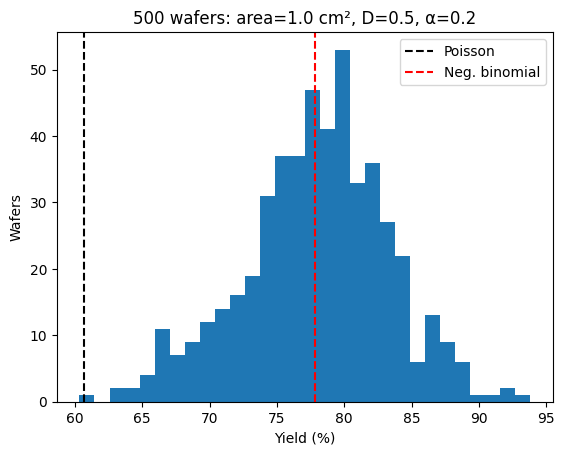

In [ ]:
AREA = 1.0          # die area (cm²)
D = 0.5             # average defects per cm²
ALPHA = 0.2         # clustering: small = clustered, 100 = almost random
N_WAFERS = 500
WAFER_COST = 10000  # dollars, an ILLUSTRATIVE number
PATCH = 5.0         # size of each "dirtiness patch" in cm

yields, total_dies, die_counts = run_sim(AREA, D, ALPHA, PATCH, N_WAFERS)
mean_y = yields.mean()

print(f"Dies per wafer:           {total_dies}")
print(f"Simulated yield:          {100*mean_y:.1f}%  (± {100*yields.std():.1f}% wafer to wafer)")
print(f"Poisson formula:          {100*poisson_yield(AREA, D):.1f}%")
print(f"Negative binomial (α={ALPHA}): {100*nb_yield(AREA, D, ALPHA):.1f}%")
print(f"α recovered (moments):    {alpha_from_moments(die_counts):.2f}")
print(f"Cost per good die:        ${cost_per_good_die(WAFER_COST, total_dies, mean_y):.2f}")

plt.hist(100 * yields, bins=30)
plt.axvline(100 * poisson_yield(AREA, D), color="k", linestyle="--", label="Poisson")
plt.axvline(100 * nb_yield(AREA, D, ALPHA), color="r", linestyle="--", label="Neg. binomial")
plt.xlabel("Yield (%)"); plt.ylabel("Wafers"); plt.legend()
plt.title(f"{N_WAFERS} wafers: area={AREA} cm², D={D}, α={ALPHA}")
plt.show()

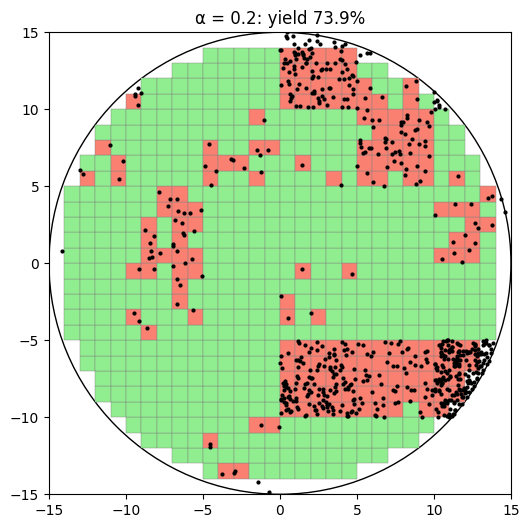

In [ ]:
from matplotlib.patches import Rectangle

side = np.sqrt(AREA)
valid, n = valid_die_grid(side)
x, y = sample_defects(D, ALPHA, PATCH)
ix = np.floor(x / side).astype(int) + n
iy = np.floor(y / side).astype(int) + n
hit = np.zeros_like(valid); hit[ix, iy] = True

fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), R, fill=False))
for i, j in zip(*np.nonzero(valid)):
    ax.add_patch(Rectangle(((i - n) * side, (j - n) * side), side, side,
                 facecolor="salmon" if hit[i, j] else "lightgreen",
                 edgecolor="gray", linewidth=0.3))
ax.scatter(x, y, s=4, color="black")
ax.set_xlim(-R, R); ax.set_ylim(-R, R); ax.set_aspect("equal")
ax.set_title(f"α = {ALPHA}: yield {100*(1 - hit[valid].mean()):.1f}%")
plt.show()

True α = 0.2, fitted α = 0.24


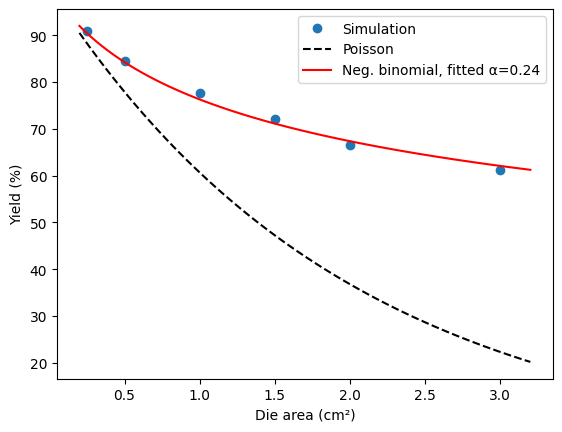

In [ ]:
TRUE_ALPHA = 0.2
areas = [0.25, 0.5, 1, 1.5, 2, 3]
sim_means = [run_sim(a, D, TRUE_ALPHA, PATCH, 300)[0].mean() for a in areas]

fitted = alpha_from_fit(areas, sim_means, D)
print(f"True α = {TRUE_ALPHA}, fitted α = {fitted:.2f}")

A_line = np.linspace(0.2, 3.2, 100)
plt.plot(areas, 100 * np.array(sim_means), "o", label="Simulation")
plt.plot(A_line, 100 * poisson_yield(A_line, D), "k--", label="Poisson")
plt.plot(A_line, 100 * nb_yield(A_line, D, fitted), "r-", label=f"Neg. binomial, fitted α={fitted:.2f}")
plt.xlabel("Die area (cm²)"); plt.ylabel("Yield (%)"); plt.legend()
plt.show()